In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importing admission data set

In [ ]:
admission_data=pd.read_csv("ADMISSIONS.csv")

In [ ]:
admission_data.head()

,row_id,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,insurance,language,religion,marital_status,ethnicity,edregtime,edouttime,diagnosis,hospital_expire_flag
0,12258,10006,142345,2164-10-23 21:09:00,2164-11-01 17:15:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,NaN,CATHOLIC,SEPARATED,BLACK/AFRICAN AMERICAN,2164-10-23 16:43:00,2164-10-23 23:00:00,SEPSIS,0
1,12263,10011,105331,2126-08-14 22:32:00,2126-08-28 18:59:00,2126-08-28 18:59:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Private,NaN,CATHOLIC,SINGLE,UNKNOWN/NOT SPECIFIED,NaN,NaN,HEPATITIS B,1
2,12265,10013,165520,2125-10-04 23:36:00,2125-10-07 15:13:00,2125-10-07 15:13:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,NaN,CATHOLIC,NaN,UNKNOWN/NOT SPECIFIED,NaN,NaN,SEPSIS,1
3,12269,10017,199207,2149-05-26 17:19:00,2149-06-03 18:42:00,NaN,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,NaN,CATHOLIC,DIVORCED,WHITE,2149-05-26 12:08:00,2149-05-26 19:45:00,HUMERAL FRACTURE,0
4,12270,10019,177759,2163-05-14 20:43:00,2163-05-15 12:00:00,2163-05-15 12:00:00,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,Medicare,NaN,CATHOLIC,DIVORCED,WHITE,NaN,NaN,ALCOHOLIC HEPATITIS,1


In [ ]:
admission_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   row_id                129 non-null    int64 
 1   subject_id            129 non-null    int64 
 2   hadm_id               129 non-null    int64 
 3   admittime             129 non-null    object
 4   dischtime             129 non-null    object
 5   deathtime             40 non-null     object
 6   admission_type        129 non-null    object
 7   admission_location    129 non-null    object
 8   insurance             129 non-null    object
 9   language              81 non-null     object
 10  religion              128 non-null    object
 11  marital_status        113 non-null    object
 12  ethnicity             129 non-null    object
 13  edregtime             92 non-null     object
 14  edouttime             92 non-null     object
 15  diagnosis             129 non-null    ob

Checking null values

In [ ]:
admission_data.isnull().sum()

row_id                   0
subject_id               0
hadm_id                  0
admittime                0
dischtime                0
deathtime               89
admission_type           0
admission_location       0
insurance                0
language                48
religion                 1
marital_status          16
ethnicity                0
edregtime               37
edouttime               37
diagnosis                0
hospital_expire_flag     0
dtype: int64

Treating null values

In [ ]:
mode_of_religion=admission_data["religion"].mode()[0]

In [ ]:
admission_data["religion"].fillna(mode_of_religion,inplace=True)

In [ ]:
admission_data.isnull().sum()

row_id                   0
subject_id               0
hadm_id                  0
admittime                0
dischtime                0
deathtime               89
admission_type           0
admission_location       0
insurance                0
language                48
religion                 0
marital_status          16
ethnicity                0
edregtime               37
edouttime               37
diagnosis                0
hospital_expire_flag     0
dtype: int64

In [ ]:
admission_data["language"].fillna("unknown",inplace=True)
admission_data["marital_status"].fillna("unknown",inplace=True)

In [ ]:
admission_data.isnull().sum()

row_id                   0
subject_id               0
hadm_id                  0
admittime                0
dischtime                0
deathtime               89
admission_type           0
admission_location       0
insurance                0
language                 0
religion                 0
marital_status           0
ethnicity                0
edregtime               37
edouttime               37
diagnosis                0
hospital_expire_flag     0
dtype: int64

In [ ]:
admission_data.describe(include="all")

,row_id,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,insurance,language,religion,marital_status,ethnicity,edregtime,edouttime,diagnosis,hospital_expire_flag
count,129.000000,129.000000,129.000000,129,129,40,129,129,129,129,129,129,129,92,92,129,129.000000
unique,NaN,NaN,NaN,129,129,40,3,5,4,6,10,7,9,92,92,95,NaN
top,NaN,NaN,NaN,2164-10-23 21:09:00,2164-11-01 17:15:00,2126-08-28 18:59:00,EMERGENCY,EMERGENCY ROOM ADMIT,Medicare,ENGL,CATHOLIC,MARRIED,WHITE,2164-10-23 16:43:00,2164-10-23 23:00:00,SEPSIS,NaN
freq,NaN,NaN,NaN,1,1,1,119,81,98,58,60,60,86,1,1,10,NaN
mean,28036.441860,28010.410853,152343.441860,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.310078
std,14036.548988,16048.502883,27858.788248,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.464328
min,12258.000000,10006.000000,100375.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,12339.000000,10088.000000,128293.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,39869.000000,40310.000000,157235.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,40463.000000,42135.000000,174739.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000


Importing patiets data

In [ ]:
pt_data=pd.read_csv("PATIENTS.csv")

In [ ]:
pt_data.head()

,row_id,subject_id,gender,dob
0,9467,10006,F,2094-03-05 0:00:00
1,9472,10011,F,2090-06-05 0:00:00
2,9474,10013,F,2038-09-03 0:00:00
3,9478,10017,F,2075-09-21 0:00:00
4,9479,10019,M,2114-06-20 0:00:00


In [ ]:

# Converting dob to datetime
pt_data['dob'] = pd.to_datetime(pt_data['dob'], errors='coerce')

# Defining a function to categorize age based on birth year
def categorize_age(dob):
    year = dob.year
    if year < 1900:
        return 'More than 89'

    else:
        return 'Less than 89'

# Apply the function to the dob column
pt_data['age_category'] = pt_data['dob'].apply(categorize_age)


In [ ]:
pt_data.head()

,row_id,subject_id,gender,dob,age_category
0,9467,10006,F,2094-03-05,Less than 89
1,9472,10011,F,2090-06-05,Less than 89
2,9474,10013,F,2038-09-03,Less than 89
3,9478,10017,F,2075-09-21,Less than 89
4,9479,10019,M,2114-06-20,Less than 89


In [ ]:
pt_data.describe(include="all")

,row_id,subject_id,gender,dob,age_category
count,100.000000,100.000000,100,100,100
unique,NaN,NaN,2,NaN,2
top,NaN,NaN,F,NaN,Less than 89
freq,NaN,NaN,55,NaN,92
mean,20452.580000,26162.330000,NaN,2062-01-12 09:36:00,NaN
min,9467.000000,10006.000000,NaN,1844-07-18 00:00:00,NaN
25%,9526.500000,10068.500000,NaN,2050-12-23 06:00:00,NaN
50%,20209.000000,25128.000000,NaN,2073-03-05 00:00:00,NaN
75%,31391.250000,42276.500000,NaN,2097-11-22 00:00:00,NaN
max,31872.000000,44228.000000,NaN,2181-04-19 00:00:00,NaN


In [ ]:
pt_data.isnull().sum()

row_id          0
subject_id      0
gender          0
dob             0
age_category    0
dtype: int64

Importing ICD code data

In [ ]:
icd_code=pd.read_csv("DIAGNOSES_ICD.csv")

In [ ]:
icd_code.head()

,row_id,subject_id,hadm_id,icd9_code
0,112344,10006,142345,99591
1,112345,10006,142345,99662
2,112346,10006,142345,5672
3,112347,10006,142345,40391
4,112348,10006,142345,42731


In [ ]:
icd_code.describe(include="all")

,row_id,subject_id,hadm_id,icd9_code
count,1761.000000,1761.000000,1761.000000,1761
unique,NaN,NaN,NaN,580
top,NaN,NaN,NaN,4019
freq,NaN,NaN,NaN,53
mean,287797.360591,30392.649631,152515.138558,NaN
std,132861.091209,15461.173204,27552.374513,NaN
min,112344.000000,10006.000000,100375.000000,NaN
25%,113177.000000,10094.000000,128293.000000,NaN
50%,382072.000000,40687.000000,155297.000000,NaN
75%,389325.000000,42199.000000,174863.000000,NaN


Importing ICD diagnosis data

In [ ]:
icd_title=pd.read_csv("D_ICD_DIAGNOSES.csv")

In [ ]:
icd_title.head()

,row_id,icd9_code,short_title,long_title
0,1,01716,Erythem nod tb-oth test,Erythema nodosum with hypersensitivity reactio...
1,2,01720,TB periph lymph-unspec,"Tuberculosis of peripheral lymph nodes, unspec..."
2,3,01721,TB periph lymph-no exam,"Tuberculosis of peripheral lymph nodes, bacter..."
3,4,01722,TB periph lymph-exam unk,"Tuberculosis of peripheral lymph nodes, bacter..."
4,5,01723,TB periph lymph-micro dx,"Tuberculosis of peripheral lymph nodes, tuberc..."


In [ ]:
icd_title.describe(include="all")

,row_id,icd9_code,short_title,long_title
count,14567.000000,14567,14567,14567
unique,NaN,14567,14328,14562
top,NaN,01716,Op skl vlt fx-concus NOS,"Longitudinal deficiency, phalanges, complete o..."
freq,NaN,1,5,2
mean,7284.000000,NaN,NaN,NaN
std,4205.275021,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3642.500000,NaN,NaN,NaN
50%,7284.000000,NaN,NaN,NaN
75%,10925.500000,NaN,NaN,NaN


**Gender Distribution, Age Groups, Ethnicity, and Marital Status**


In [ ]:


# Gender Distribution
print("Gender Distribution:\n", pt_data['gender'].value_counts())

print(30*"--")

# Age Categories
print("Age Categories:\n", pt_data['age_category'].value_counts())

print(30*"--")

# Ethnicity Distribution
print("Ethnicity Distribution:\n", admission_data['ethnicity'].value_counts())

print(30*"--")

# Marital Status Distribution
print("Marital Status Distribution:\n", admission_data['marital_status'].value_counts())


Gender Distribution:
 gender
F    55
M    45
Name: count, dtype: int64
------------------------------------------------------------
Age Categories:
 age_category
Less than 89    92
More than 89     8
Name: count, dtype: int64
------------------------------------------------------------
Ethnicity Distribution:
 ethnicity
WHITE                                                       86
HISPANIC/LATINO - PUERTO RICAN                              15
UNKNOWN/NOT SPECIFIED                                       11
BLACK/AFRICAN AMERICAN                                       7
OTHER                                                        3
ASIAN                                                        2
HISPANIC OR LATINO                                           2
AMERICAN INDIAN/ALASKA NATIVE FEDERALLY RECOGNIZED TRIBE     2
UNABLE TO OBTAIN                                             1
Name: count, dtype: int64
------------------------------------------------------------
Marital Status Distribut

**Analyzing Hospital Admissions per Patient to Identify Readmissions Patterns**

In [ ]:


# Calculating the number of admissions per patient
admissions_count = admission_data.groupby('subject_id').size()

# Sorting the results in descending order based on the count of admissions
sorted_admissions_count = admissions_count[admissions_count > 1].sort_values(ascending=False)

# Printing the sorted list of patients with multiple admissions
print("Patients with multiple admissions (sorted in descending order):\n", sorted_admissions_count)


Patients with multiple admissions (sorted in descending order):
 subject_id
41976    15
10088     3
44083     3
10059     2
10094     2
10117     2
10119     2
10124     2
40124     2
40310     2
41795     2
42135     2
42346     2
43881     2
dtype: int64


**Most Frequent Admission Types**

In [ ]:
print("Admission Types Frequency:\n", admission_data['admission_type'].value_counts())


Admission Types Frequency:
 admission_type
EMERGENCY    119
ELECTIVE       8
URGENT         2
Name: count, dtype: int64


**Identifing the Most Frequent ICD-9 Diagnoses**

In [ ]:
icd9_counts = icd_code['icd9_code'].value_counts().head()
print("Most Frequent ICD-9 Codes:\n", icd_title[icd_title['icd9_code'].isin(icd9_counts.index)][['icd9_code', 'long_title']])


Most Frequent ICD-9 Codes:
      icd9_code                             long_title
4303      4019     Unspecified essential hypertension
4461     42731                    Atrial fibrillation
4472      4280  Congestive heart failure, unspecified
5278     51881              Acute respiratory failure
5907      5849      Acute kidney failure, unspecified


**Investigating Associations between Diagnoses and Patient Outcomes**

In [ ]:
diagnosis_outcome = pd.merge(icd_code, admission_data[['subject_id', 'hospital_expire_flag']], on='subject_id')
frequent_diagnosis_outcome = diagnosis_outcome[diagnosis_outcome['icd9_code'].isin(icd9_counts.index)]
print("Outcomes for Frequent Diagnoses:\n", frequent_diagnosis_outcome.groupby('icd9_code')['hospital_expire_flag'].mean())


Outcomes for Frequent Diagnoses:
 icd9_code
4019     0.059524
42731    0.067265
4280     0.235294
51881    0.202381
5849     0.086735
Name: hospital_expire_flag, dtype: float64



ICD-9 Code 4019: This is typically associated with unspecified essential hypertension. The mortality rate for patients with this diagnosis in your data is approximately 5.95%.

ICD-9 Code 42731: This code represents atrial fibrillation. The mortality rate for patients diagnosed with atrial fibrillation is about 6.73%.


ICD-9 Code 4280: Represents congestive heart failure. The mortality rate for this condition is significantly higher at approximately 23.53%.


ICD-9 Code 51881: This code is used for acute respiratory failure. Patients with this diagnosis had a mortality rate of approximately 20.24%.


ICD-9 Code 5849: Corresponds to acute kidney failure, unspecified. The mortality rate here is approximately 8.67%.



**Identifing Associations with Readmission Rates**

In [ ]:
admission_data['readmission'] = admission_data.duplicated(subset=['subject_id'], keep=False)
readmission_diagnosis = pd.merge(icd_code, admission_data[['hadm_id', 'readmission']], on='hadm_id')
print("Readmission Rates by Diagnosis:\n", readmission_diagnosis.groupby('icd9_code')['readmission'].mean())


Readmission Rates by Diagnosis:
 icd9_code
1120     1.000000
1122     0.500000
1124     0.000000
1179     0.000000
1508     1.000000
           ...   
V5867    0.750000
V600     1.000000
V667     0.333333
V8741    0.333333
V8801    0.000000
Name: readmission, Length: 580, dtype: float64


In [ ]:

# Calculating readmission rates by diagnosis
readmission_rates = readmission_diagnosis.groupby('icd9_code')['readmission'].mean()
# Filtering out diagnosis codes with a 100% readmission rate
filtered_readmission_rates = readmission_rates[readmission_rates == 1.0]

print("Readmission Rates by Diagnosis ( 100% rates):\n", filtered_readmission_rates)

print(30*"--")

# counting diagnosis codes with a 100% readmission rate
filtered_readmission_rates_count = readmission_rates[readmission_rates == 1.0].count()
print("count of Diagnosis (100% rates):\n", filtered_readmission_rates_count)

Readmission Rates by Diagnosis ( 100% rates):
 icd9_code
1120     1.0
1508     1.0
20020    1.0
20300    1.0
2273     1.0
        ... 
V4983    1.0
V4984    1.0
V4986    1.0
V5413    1.0
V600     1.0
Name: readmission, Length: 110, dtype: float64
------------------------------------------------------------
count of Diagnosis (100% rates):
 110


**Calculating In-Hospital Mortality Rates for Different Diagnoses and Admission Types**

In [ ]:
print("Mortality by Diagnosis:\n", frequent_diagnosis_outcome.groupby('icd9_code')['hospital_expire_flag'].mean())

print(30*"--")
print("Mortality by Admission Type:\n", admission_data.groupby('admission_type')['hospital_expire_flag'].mean())


Mortality by Diagnosis:
 icd9_code
4019     0.059524
42731    0.067265
4280     0.235294
51881    0.202381
5849     0.086735
Name: hospital_expire_flag, dtype: float64
------------------------------------------------------------
Mortality by Admission Type:
 admission_type
ELECTIVE     0.000000
EMERGENCY    0.327731
URGENT       0.500000
Name: hospital_expire_flag, dtype: float64


**Analysing Correlations between Patient Demographics and Mortality Rates**

In [ ]:


# Merging pt_data with admission_data to include gender and other demographic data
combined_data = pd.merge(admission_data, pt_data[['subject_id', 'gender']], on='subject_id')

# Calculating mortality rates by gender
mortality_by_gender = combined_data.groupby('gender')['hospital_expire_flag'].mean()

# Printing mortality by gender
print("Mortality by Gender:\n", mortality_by_gender)

print(30*"__")

# Since 'ethnicity' is in admission_data, we can calculate mortality by ethnicity directly
mortality_by_ethnicity = admission_data.groupby('ethnicity')['hospital_expire_flag'].mean()

# Printing mortality by ethnicity
print("Mortality by Ethnicity:\n", mortality_by_ethnicity)


Mortality by Gender:
 gender
F    0.355932
M    0.271429
Name: hospital_expire_flag, dtype: float64
____________________________________________________________
Mortality by Ethnicity:
 ethnicity
AMERICAN INDIAN/ALASKA NATIVE FEDERALLY RECOGNIZED TRIBE    0.500000
ASIAN                                                       0.500000
BLACK/AFRICAN AMERICAN                                      0.285714
HISPANIC OR LATINO                                          0.500000
HISPANIC/LATINO - PUERTO RICAN                              0.000000
OTHER                                                       0.666667
UNABLE TO OBTAIN                                            1.000000
UNKNOWN/NOT SPECIFIED                                       0.454545
WHITE                                                       0.313953
Name: hospital_expire_flag, dtype: float64


**Calculating Readmission Rates for Specific Conditions with High Readmission Rates**

In [ ]:


# Marking duplicates based on 'subject_id' to identify readmissions
admission_data['readmission'] = admission_data.duplicated(subset=['subject_id'], keep=False)

# Merging icd_code data with readmission flags from admission_data
readmission_diagnosis = pd.merge(icd_code, admission_data[['hadm_id', 'readmission']], on='hadm_id')

# Now also merge in the icd_title to get descriptive titles for each code
readmission_diagnosis_with_titles = pd.merge(readmission_diagnosis, icd_title[['icd9_code', 'short_title', 'long_title']], on='icd9_code')

# Calculating readmission rates by diagnosis, including descriptive titles
readmission_rates_with_titles = readmission_diagnosis_with_titles.groupby(['icd9_code', 'short_title', 'long_title'])['readmission'].mean()

# Printing readmission rates along with ICD-9 code titles
print("Readmission Rates by Diagnosis with Titles:\n", readmission_rates_with_titles)


Readmission Rates by Diagnosis with Titles:
 icd9_code  short_title               long_title                                             
1120       Thrush                    Candidiasis of mouth                                       1.000000
1122       Candidias urogenital NEC  Candidiasis of other urogenital sites                      0.500000
1124       Candidiasis of lung       Candidiasis of lung                                        0.000000
1179       Mycoses NEC & NOS         Other and unspecified mycoses                              0.000000
1508       Mal neo esophagus NEC     Malignant neoplasm of other specified part of esophagus    1.000000
                                                                                                  ...   
V5867      Long-term use of insulin  Long-term (current) use of insulin                         0.750000
V600       Lack of housing           Lack of housing                                            1.000000
V667       Encountr pa

In [ ]:


# Convert 'admittime' to datetime if not already
admission_data['admittime'] = pd.to_datetime(admission_data['admittime'])

# Extract hour, day of the week, and month
admission_data['hour'] = admission_data['admittime'].dt.hour
admission_data['day_of_week'] = admission_data['admittime'].dt.day_name()
admission_data['month'] = admission_data['admittime'].dt.month


<ipython-input-159-acdd7252994d>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='hour', data=admission_data, palette='viridis')


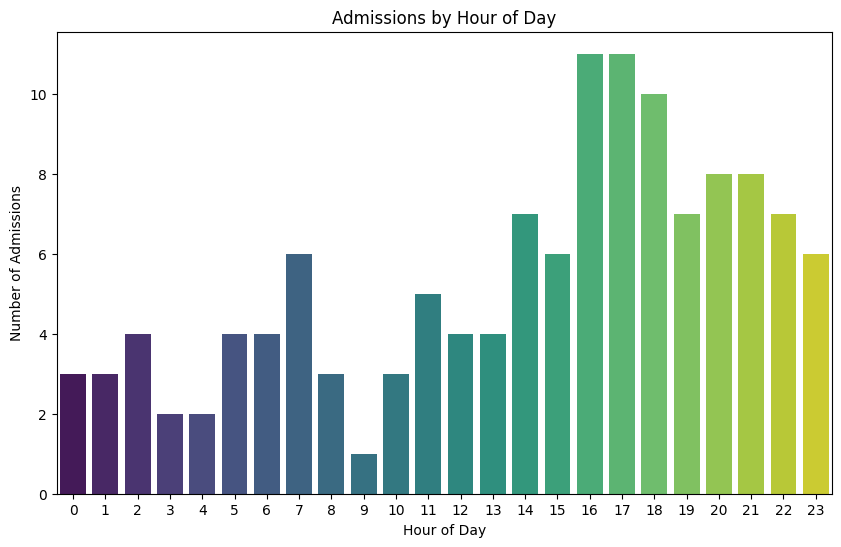

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='hour', data=admission_data, palette='viridis')
plt.title('Admissions by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Admissions')
plt.xticks(rotation=0)
plt.show()


<ipython-input-160-7d3bd048902f>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='day_of_week', data=admission_data, order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette='colorblind')


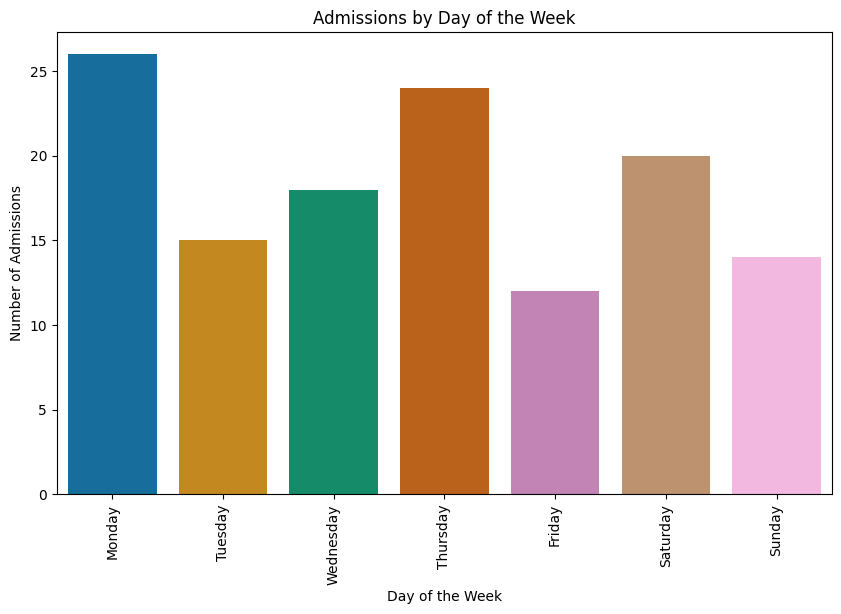

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='day_of_week', data=admission_data, order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette='colorblind')
plt.title('Admissions by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Admissions')
plt.xticks(rotation=90)
plt.show()


<ipython-input-161-0007a03fa449>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='month', data=admission_data, palette='coolwarm')


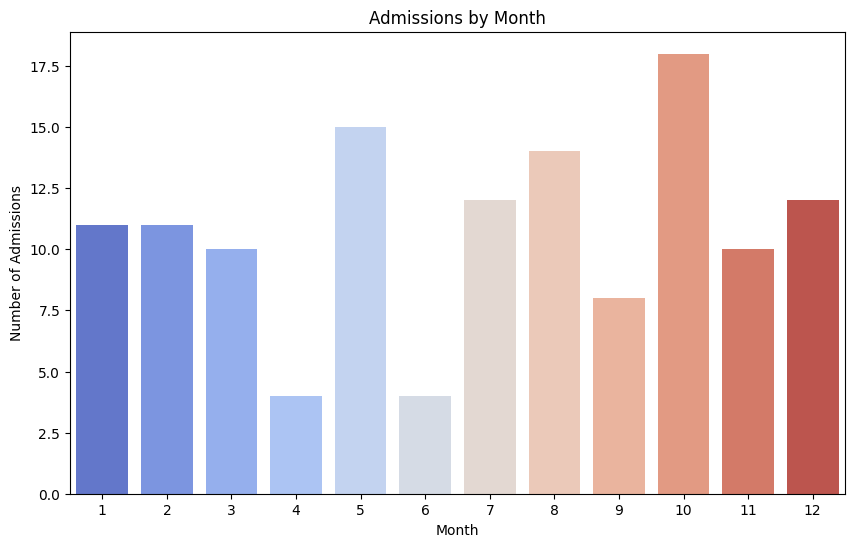

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='month', data=admission_data, palette='coolwarm')
plt.title('Admissions by Month')
plt.xlabel('Month')
plt.ylabel('Number of Admissions')
plt.xticks(rotation=0)
plt.show()


In [ ]:

# Ensuring 'admittime' is in datetime format
admission_data['admittime'] = pd.to_datetime(admission_data['admittime'])

# Extracting the hour from 'admittime'
admission_data['hour'] = admission_data['admittime'].dt.hour

# Filtering data to include only relevant admission types
relevant_types = ['ELECTIVE', 'URGENT', 'NEWBORN', 'EMERGENCY']
filtered_data = admission_data[admission_data['admission_type'].isin(relevant_types)]


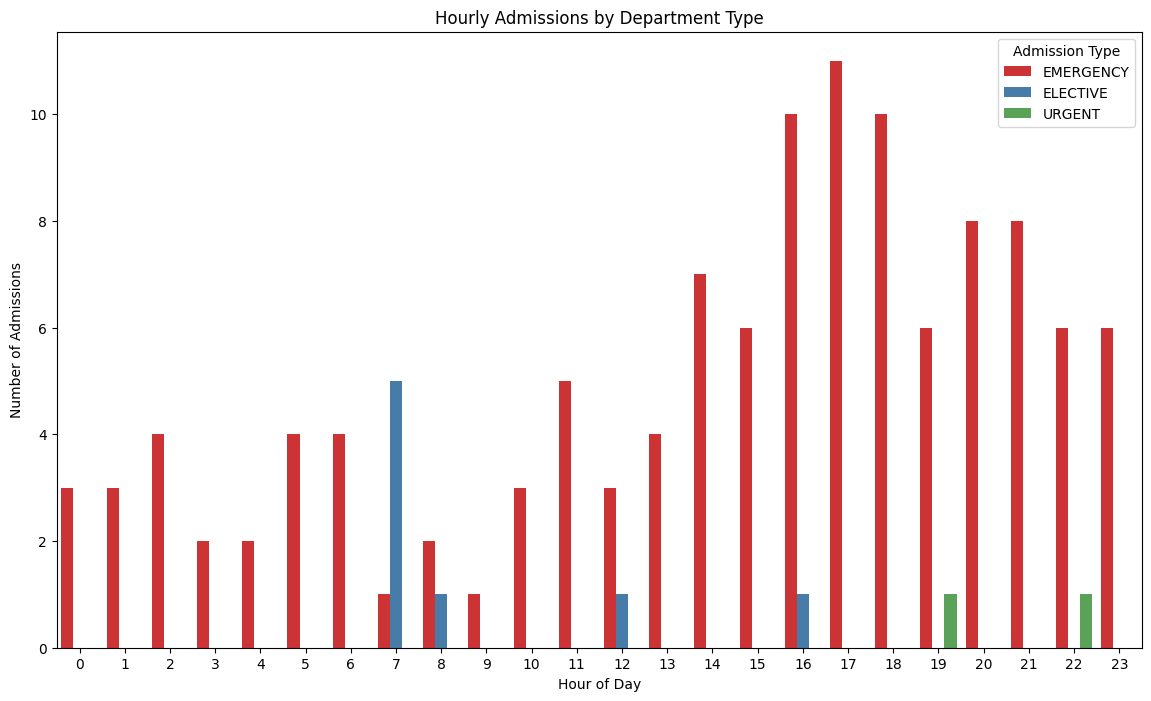

In [ ]:
plt.figure(figsize=(14, 8))
sns.countplot(x='hour', hue='admission_type', data=filtered_data, palette='Set1')
plt.title('Hourly Admissions by Department Type')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Admissions')
plt.legend(title='Admission Type')
plt.xticks(rotation=0)
plt.show()


# **Key Findings and Insights from the Analysis**

**Demographics and Admission Characteristics**:

**Gender Distribution**: There is a slightly higher number of female patients (55) compared to male patients (45).

**Age Categories**: A majority of the patient population (92 out of 100) falls into the "Less than 89" age category.

**Ethnicity Distribution:** The majority of patients are classified as White (86), with other ethnicities such as Hispanic/Latino and Black/African American making up smaller proportions.

**Marital Status**: The most common marital status is Married (60), followed by Single (26) and Widowed (15).

**Admission Types:** Emergency admissions dominate (119 out of 129), indicating a high frequency of urgent care needs among the patient population.

**Hospital Admissions and Readmissions:**

Multiple admissions are observed in several patients, with one patient having as many as 15 admissions, suggesting a pattern of frequent readmissions or chronic conditions among certain individuals.

**Diagnosis Analysis:**

**Most Frequent Diagnoses**: Conditions like unspecified essential hypertension, atrial fibrillation, congestive heart failure, acute respiratory failure, and acute kidney failure are most common, indicating prevalent cardiovascular and renal issues.

**Diagnosis and Outcomes**: High mortality rates are particularly notable for congestive heart failure (23.53%) and acute respiratory failure (20.24%), suggesting these conditions are particularly severe among the patient cohort.

**Mortality Analysis:**

**Mortality by Admission Type**: Emergency admissions have a higher mortality rate (32.77%) compared to Elective and Urgent, reflecting the serious nature of conditions treated in emergency scenarios.

**Mortality by Demographics**: Mortality rates vary by gender and ethnicity, with females exhibiting a slightly higher mortality rate (35.59%) compared to males (27.14%).

**Readmission Analysis:**

Specific conditions such as candidiasis of the mouth, malignant neoplasm of other specified parts of the esophagus, and lack of housing are associated with a 100% readmission rate, highlighting specific areas where patient management could be improved to prevent frequent readmissions.

**Temporal Analysis of Admissions:**

Analysis of admissions by the hour of the day, day of the week, and month reveal patterns likely related to the nature of the hospital's emergency services and elective procedures. For instance, elective admissions likely peak on weekdays during morning hours.

Seasonal trends are evident, with possible peaks during certain months, suggesting external factors such as flu seasons or public holidays affecting admission rates.

**Recommendations**:

**Enhance Chronic Disease Management:**
Develop or improve existing chronic disease management programs, especially for cardiovascular and respiratory conditions, to reduce the incidence of emergency admissions and readmissions.

**Targeted Interventions for High-Risk Patients:**

Implement targeted interventions for patients with frequent admissions to address underlying issues such as socioeconomic factors (e.g., housing), which may contribute to their health status.

**Improve Post-Discharge Care and Follow-Up:**

Enhance follow-up care for patients discharged after treatments for conditions with high mortality and readmission rates. This could include more rigorous post-discharge monitoring and support.

**Cultural and Language Considerations in Patient Care:**

Address the diverse cultural and linguistic needs of the patient population, especially given the significant number of patients with different ethnic backgrounds and languages.